# 09 · Final chronological holdout

The question is whether the frozen XGBoost forecast improves on the training prior and whether its long/cash rule beats Buy & Hold after trading fees on new dates. Phase 2 trained the estimator on 2005–2018. Phase 4 selected the 0.50 threshold using 2019–2021. The model, threshold, cost assumptions, benchmarks and uncertainty measures are recorded in `reports/phase5/frozen_protocol.json` before the evaluation. No refit or test-period model search is part of this experiment.

The price series uses retrospective vendor adjustments. All returns below are research estimates. Inference relies on the stability of the sampled time series.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from quant_trading.backtest import run_backtest
from quant_trading.performance import compute_performance
from quant_trading.ml import probability_metrics
from quant_trading.robustness import moving_block_bootstrap, observation_log_loss
from quant_trading.data import sha256_file

cwd = Path.cwd().resolve()
root = next(p for p in (cwd, *cwd.parents) if (p / 'src/quant_trading/pipeline.py').is_file())
report = root / 'reports/phase5'
protocol = json.loads((report / 'frozen_protocol.json').read_text())
for filename, expected in protocol['sha256'].items():
    if sha256_file(root / filename) != expected:
        raise ValueError(f'Frozen input has changed: {filename}')
test = pd.read_parquet(root / 'data/processed/spy_test.parquet')
assert len(test) == protocol['test_rows']
assert [test.index[0].date().isoformat(), test.index[-1].date().isoformat()] == protocol['test_signal_dates']
model = XGBClassifier()
model.load_model(root / protocol['model_file'])
features = test[protocol['feature_columns']]
assert features.columns.tolist() == model.get_booster().feature_names
p = pd.Series(model.predict_proba(features)[:, 1].astype(float), index=test.index)
prior = np.full(len(p), protocol['prior'])
y = test.label.to_numpy()
print(f'{len(test):,} signals, {test.index[0].date()} to {test.index[-1].date()}')

1,210 signals, 2022-01-03 to 2026-10-28


## Probability forecasts

In [2]:
forecast = pd.DataFrame([{'forecast': name, **probability_metrics(y, probs)}
                         for name, probs in [('Training prior', prior), ('XGBoost', p)]])
forecast.to_csv(report / 'forecast_metrics.csv', index=False)
print(forecast.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

      forecast  log_loss  brier_score  roc_auc  observed_positive_rate  mean_predicted_probability
Training prior  0.690487     0.248671 0.500000                0.537190                    0.544534
       XGBoost  0.695135     0.250959 0.483330                0.537190                    0.535341


## Trading outcome after costs

        portfolio  cumulative_return     cagr  sharpe_ratio  max_drawdown  market_exposure  one_sided_trades  final_equity
XGBoost long/cash           0.500797 0.087907      0.606006      0.192255         0.859504               147  15007.969258
       Buy & Hold           0.691898 0.115306      0.716386      0.263226         1.000000                 1  16918.979188


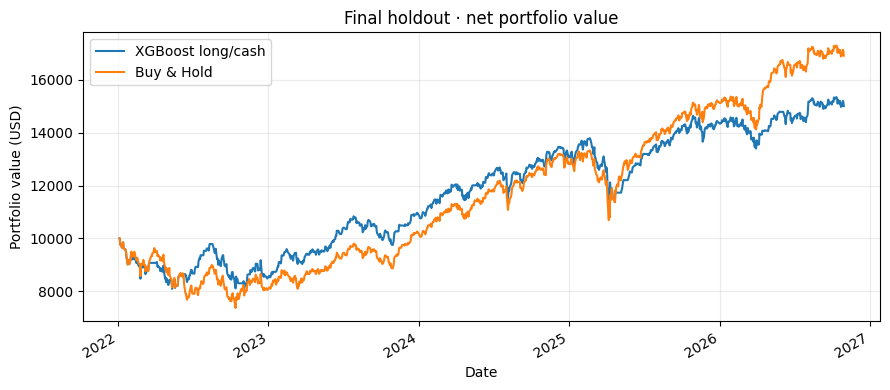

In [3]:
capital = protocol['capital']
cost = protocol['cost_bps']
strategy = run_backtest(test, p, threshold=protocol['threshold'], cost_bps=cost, initial_capital=capital)
benchmark = run_backtest(test, cost_bps=cost, initial_capital=capital)
portfolios = {'XGBoost long/cash': strategy, 'Buy & Hold': benchmark}
performance = pd.DataFrame([{'portfolio': name, 'final_equity': trades.equity.iloc[-1],
                             **compute_performance(trades, initial_capital=capital)}
                            for name, trades in portfolios.items()])
performance.to_csv(report / 'performance.csv', index=False)
daily = strategy.copy()
daily['actual_label'] = y
daily['p_prior'] = prior
daily['benchmark_net_return'] = benchmark.net_return
daily['benchmark_equity'] = benchmark.equity
daily.to_csv(report / 'daily_results.csv', index_label='exit_date')
print(performance[['portfolio','cumulative_return','cagr','sharpe_ratio','max_drawdown',
                   'market_exposure','one_sided_trades','final_equity']].to_string(index=False))
ax = plt.subplots(figsize=(9,4))[1]
for name, trades in portfolios.items():
    start = pd.Series([capital], index=[trades.entry_date.iloc[0]])
    pd.concat([start, trades.equity]).plot(ax=ax, label=name)
ax.set(ylabel='Portfolio value (USD)', xlabel='Date', title='Final holdout · net portfolio value')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## Paired uncertainty estimates

Percentile moving-block intervals use 2,000 draws of contiguous observations and a prespecified primary block of 10 sessions. Positive return differences favor XGBoost. Negative loss differences favor XGBoost.

In [4]:
differences = {
    'XGBoost minus prior log loss': observation_log_loss(y, p) - observation_log_loss(y, prior),
    'XGBoost minus Buy & Hold daily return (bps)': 10000 * (strategy.net_return - benchmark.net_return),
}
rows = []
for name, values in differences.items():
    for length in protocol['block_lengths']:
        result = moving_block_bootstrap(values, block_length=length,
                                        n_bootstrap=protocol['bootstrap_draws'], seed=protocol['seed'])
        rows.append({'comparison': name, 'block_length': length, 'mean': result['mean_difference'],
                     'ci_lower': result['ci_lower'], 'ci_upper': result['ci_upper']})
intervals = pd.DataFrame(rows)
intervals.to_csv(report / 'paired_intervals.csv', index=False)
print(intervals.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

                                 comparison  block_length      mean  ci_lower  ci_upper
               XGBoost minus prior log loss             5  0.004648  0.000220  0.009390
               XGBoost minus prior log loss            10  0.004648 -0.000008  0.009100
               XGBoost minus prior log loss            20  0.004648  0.000412  0.009308
XGBoost minus Buy & Hold daily return (bps)             5 -1.078354 -3.514238  1.533536
XGBoost minus Buy & Hold daily return (bps)            10 -1.078354 -3.594978  1.778886
XGBoost minus Buy & Hold daily return (bps)            20 -1.078354 -3.887101  1.840680


## Interpretation

Over the 1,210 held-out open-to-open returns, XGBoost had a log loss of 0.69514 and ROC-AUC of 0.48333. The constant training prior had a lower log loss of 0.69049. The strategy grew $10,000 to $15,007.97 after fees, against $16,918.98 for Buy & Hold. It held SPY on 85.95% of the return intervals. Maximum drawdown magnitude was 19.23%, versus 26.32% for Buy & Hold.

The mean daily net return difference was −1.08 basis points. The prespecified 95% moving-block bootstrap interval was [−3.59, +1.78] basis points per day. The realized shortfall is clear, while the interval includes zero. The experiment supplies no evidence of economic outperformance or an improvement in probabilistic forecasts. The drawdown reduction occurred with lower average market exposure. Future strategy changes require fresh data for an independent final assessment.